# 03: Call celltypes via `CAS`
tutorial: https://colab.research.google.com/drive/1m9zgqP5n7E4pGGCg5RjfvlCnS6uqUdSa#scrollTo=jsU-CeHyIYhU

In [1]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
import sopa
from pathlib import Path
from spatialdata.models import TableModel, Labels2DModel
import anndata as ad
import squidpy as sq
import dask.array as da
import matplotlib.pyplot as plt
import scanpy as sc

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


In [2]:
!pip install --no-cache-dir cellarium-cas[vis]

zsh:1: no matches found: cellarium-cas[vis]


In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")
halfbrain_path = data_dir / Path("quarterbrain_sdata.zarr")
quarterbrain_path = data_dir / Path("quarterbrain_sdata_measured.zarr")

In [3]:
sdata_quarterbrain = sd.read_zarr(quarterbrain_path)
sdata_quarterbrain

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kw

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata_measured.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 25589, 46923), (5, 12794, 23461), (5, 6397, 11730), (5, 3198, 5865), (5, 1599, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (25589, 46923), (12794, 23461), (6397, 11730), (3198, 5865), (1599, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      ├── 'gexp': AnnData (38996, 960)
      └── 'morphology': AnnData (38996, 1739)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 1739 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(
/tmp/ipykernel_3799293/3072231957.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(quarterbrain_adata)


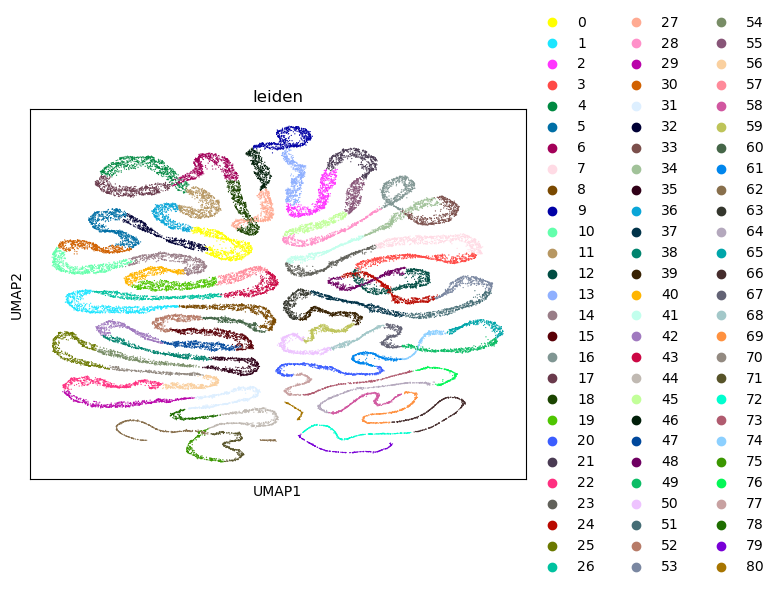

In [7]:
quarterbrain_adata = sdata_quarterbrain.tables["morphology"]

sc.pp.neighbors(quarterbrain_adata)
sc.tl.umap(quarterbrain_adata)
sc.tl.leiden(quarterbrain_adata)
sc.pl.umap(quarterbrain_adata, color="leiden")

In [17]:
quarterbrain_adata.var_names_make_unique()
data = quarterbrain_adata.to_df()

scaler = RobustMAD(epsilon=1e-18)
fitted_scaler = scaler.fit(data)
fitted_scaled = fitted_scaler.transform(data)

data_scaled = pd.DataFrame(
    fitted_scaled,
    columns=data.columns,
    index=data.index,
)
data_scaled

,axis_major_length,area,axis_minor_length,area_filled,inertia_tensor_0x0,inertia_tensor_0x1,inertia_tensor_1x0,inertia_tensor_1x1,area_convex,feret_diameter_max,...,solidity_3_4,feret_diameter_max_3_4,Correlation_Costes_1_3_4,Correlation_Costes_2_3_4,Correlation_Pearson_3_4,Correlation_Slope_3_4,Correlation_Manders_1_3_4,Correlation_Manders_2_3_4,Correlation_RWC_1_3_4,Correlation_RWC_2_3_4
cell_1,-0.885055,-0.829468,-0.856504,-0.830442,-1.113423,-0.207504,-0.207504,-0.407632,-0.890293,-0.909643,...,1.131146,-0.909643,-0.674491,-1.000000e+18,-0.587249,-5.875699,-2.002960e+17,0.883751,-0.836134,0.379856
cell_2,-1.042734,-1.463996,-2.192881,-1.464971,-0.636652,0.023557,0.023557,-1.521721,-1.456446,-1.086226,...,0.578750,-1.086226,3311.588489,0.000000e+00,1.505184,4.716731,-1.248477e+17,-0.473178,-1.928825,-0.628469
cell_3,0.165945,-0.316777,-0.590989,-0.317751,0.833677,0.366725,0.366725,-0.868649,-0.401899,0.090292,...,0.675608,0.090292,-0.674491,-1.000000e+18,0.116462,-0.773816,0.000000e+00,-0.662319,-0.429907,-0.678522
cell_4,0.086446,0.355765,0.369666,0.354790,-0.128629,-0.999360,-0.999360,0.573640,0.195707,0.057804,...,0.962614,0.057804,-0.674491,-1.000000e+18,-0.098094,-1.971274,-1.318814e+17,-0.623578,-0.515603,-0.655495
cell_5,0.745575,0.165699,-0.321721,0.164724,1.759371,0.284864,0.284864,-0.715970,0.071643,0.699556,...,0.258605,0.699556,-0.674491,-1.000000e+18,-0.571995,-6.227905,-1.780684e+17,-0.675862,-0.593751,-0.690723
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cell_38992,1.466690,0.247573,0.186184,0.248548,3.063355,0.938810,0.938810,-0.348787,1.082505,1.300332,...,-8.370587,1.300332,897.556577,0.000000e+00,-0.082071,0.075175,0.000000e+00,0.320201,0.064849,0.608041
cell_38993,-1.901759,-1.569263,-2.026870,-1.570238,-1.448551,0.397548,0.397548,-1.360995,-1.543815,-1.955931,...,-0.196386,-1.955931,3311.588489,0.000000e+00,2.694818,0.683008,0.000000e+00,0.883751,0.768815,1.408972
cell_38994,-0.778929,-1.359703,-2.041875,-1.360678,-0.433026,-0.674504,-0.674504,-1.416679,-1.284328,-0.841996,...,-2.857373,-0.841996,3311.588489,0.000000e+00,1.851764,0.864571,-1.698295e+17,0.565284,-0.850839,0.252782
cell_38995,-0.630357,-1.480566,-2.435152,-1.481540,-0.199790,0.145308,0.145308,-1.574361,-1.463435,-0.821622,...,0.046364,-0.821622,-0.674491,-1.000000e+18,-1.178942,-1.827563,0.000000e+00,0.883751,0.245501,0.569401


In [18]:
feature_select_opts = [
    "variance_threshold",
    "drop_na_columns",
    "correlation_threshold",
    "blocklist",
    "drop_outliers",
]

data_scaled_filtered = pycytominer.feature_select(
    profiles=data_scaled,
    features=data_scaled.columns.tolist(),
    samples="all",
    operation=feature_select_opts,
)
data_scaled_filtered

,intensity_max_1,intensity_std_1,RadialDistribution_FracAtD_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_RadialCV_2of4_0,RadialDistribution_FracAtD_3of4_0,RadialDistribution_RadialCV_3of4_0,RadialDistribution_FracAtD_4of4_0,RadialDistribution_RadialCV_4of4_0,...,Correlation_RWC_1_2_3,Correlation_RWC_2_2_3,extent_2_4,inertia_tensor_eigvals_0_2_4,Correlation_Pearson_2_4,Correlation_Slope_2_4,Correlation_RWC_1_2_4,Correlation_RWC_2_2_4,Correlation_Pearson_3_4,Correlation_Slope_3_4
cell_1,-0.838556,-1.151200,-0.465966,-2.569268,0.673242,1.044857,-0.798197,0.196723,0.602685,3.568707,...,0.797384,0.188688,2.305662,-0.799336,-0.044916,-0.337272,-0.804344,-0.247590,-0.587249,-5.875699
cell_2,1.184916,0.710155,-0.332243,-3.009912,0.149095,-1.333311,-0.491119,-1.231337,0.680454,0.594018,...,-0.628074,-1.333933,-0.090281,-0.917016,1.492687,1.686613,-1.355669,-0.309956,1.505184,4.716731
cell_3,1.075539,-0.049245,0.305399,-0.858328,0.132322,-1.521250,-0.181989,-1.466531,-0.249231,0.199384,...,-0.690715,-0.511925,-0.037787,0.176103,-0.798099,-1.898711,-1.237018,-0.489188,0.116462,-0.773816
cell_4,2.734422,1.183231,0.975121,-0.467980,-1.077004,-0.106967,0.750033,0.656322,-0.654594,-0.532760,...,-0.578686,0.170622,1.236226,0.090704,0.528572,1.291979,-1.631062,-1.045929,-0.098094,-1.971274
cell_5,2.132849,0.185386,1.688574,-0.002942,-0.111506,-0.683372,-0.808593,-1.657997,-0.754068,-2.337624,...,-0.679980,0.432760,-0.516776,0.856209,0.433736,0.645912,-1.456738,-0.998003,-0.571995,-6.227905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cell_38992,-0.473966,-0.297617,-1.552459,-0.121509,0.619974,-1.556993,-0.234801,-0.448824,1.170476,0.963483,...,0.070216,-1.668727,-2.435277,1.843394,0.511544,0.476217,0.710563,0.985898,-0.082071,0.075175
cell_38993,-0.036459,0.226979,-0.905696,-3.134335,0.052871,-2.374567,0.914345,-0.943624,-0.067914,2.381334,...,1.009621,0.571016,-0.131599,-1.426778,2.718391,0.486961,0.714740,1.228823,2.694818,0.683008
cell_38994,2.005243,0.414412,-0.282706,-0.200054,-0.284761,-0.670311,0.204518,-0.271617,0.361275,3.254682,...,0.270564,-2.242032,-0.989400,-0.715921,0.685648,1.237043,-1.182765,-0.690536,1.851764,0.864571
cell_38995,-0.328131,-0.747288,-0.092465,-0.074621,-0.331765,1.807393,-1.455797,3.114913,1.890039,2.987862,...,0.872958,-0.245261,0.444975,-0.593452,-0.689161,-3.863624,-0.181190,-0.165151,-1.178942,-1.827563


In [33]:
data_scaled_filtered.index = sdata_quarterbrain.tables["gexp"].obs_names
data_scaled_filtered

,intensity_max_1,intensity_std_1,RadialDistribution_FracAtD_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_RadialCV_2of4_0,RadialDistribution_FracAtD_3of4_0,RadialDistribution_RadialCV_3of4_0,RadialDistribution_FracAtD_4of4_0,RadialDistribution_RadialCV_4of4_0,...,Correlation_RWC_1_2_3,Correlation_RWC_2_2_3,extent_2_4,inertia_tensor_eigvals_0_2_4,Correlation_Pearson_2_4,Correlation_Slope_2_4,Correlation_RWC_1_2_4,Correlation_RWC_2_2_4,Correlation_Pearson_3_4,Correlation_Slope_3_4
0,-0.838556,-1.151200,-0.465966,-2.569268,0.673242,1.044857,-0.798197,0.196723,0.602685,3.568707,...,0.797384,0.188688,2.305662,-0.799336,-0.044916,-0.337272,-0.804344,-0.247590,-0.587249,-5.875699
1,1.184916,0.710155,-0.332243,-3.009912,0.149095,-1.333311,-0.491119,-1.231337,0.680454,0.594018,...,-0.628074,-1.333933,-0.090281,-0.917016,1.492687,1.686613,-1.355669,-0.309956,1.505184,4.716731
2,1.075539,-0.049245,0.305399,-0.858328,0.132322,-1.521250,-0.181989,-1.466531,-0.249231,0.199384,...,-0.690715,-0.511925,-0.037787,0.176103,-0.798099,-1.898711,-1.237018,-0.489188,0.116462,-0.773816
3,2.734422,1.183231,0.975121,-0.467980,-1.077004,-0.106967,0.750033,0.656322,-0.654594,-0.532760,...,-0.578686,0.170622,1.236226,0.090704,0.528572,1.291979,-1.631062,-1.045929,-0.098094,-1.971274
4,2.132849,0.185386,1.688574,-0.002942,-0.111506,-0.683372,-0.808593,-1.657997,-0.754068,-2.337624,...,-0.679980,0.432760,-0.516776,0.856209,0.433736,0.645912,-1.456738,-0.998003,-0.571995,-6.227905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38991,-0.473966,-0.297617,-1.552459,-0.121509,0.619974,-1.556993,-0.234801,-0.448824,1.170476,0.963483,...,0.070216,-1.668727,-2.435277,1.843394,0.511544,0.476217,0.710563,0.985898,-0.082071,0.075175
38992,-0.036459,0.226979,-0.905696,-3.134335,0.052871,-2.374567,0.914345,-0.943624,-0.067914,2.381334,...,1.009621,0.571016,-0.131599,-1.426778,2.718391,0.486961,0.714740,1.228823,2.694818,0.683008
38993,2.005243,0.414412,-0.282706,-0.200054,-0.284761,-0.670311,0.204518,-0.271617,0.361275,3.254682,...,0.270564,-2.242032,-0.989400,-0.715921,0.685648,1.237043,-1.182765,-0.690536,1.851764,0.864571
38994,-0.328131,-0.747288,-0.092465,-0.074621,-0.331765,1.807393,-1.455797,3.114913,1.890039,2.987862,...,0.872958,-0.245261,0.444975,-0.593452,-0.689161,-3.863624,-0.181190,-0.165151,-1.178942,-1.827563


In [34]:
quarterbrain_adata_filtered = ad.AnnData(
    X=data_scaled_filtered,
    obs=sdata_quarterbrain.tables["gexp"].obs,
)
quarterbrain_adata_filtered

AnnData object with n_obs × n_vars = 38996 × 479
    obs: 'fov', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'region', 'leiden'

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 479 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(


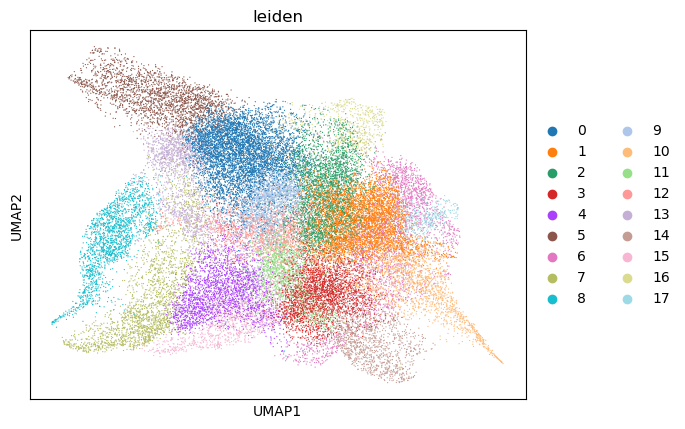

In [35]:
del quarterbrain_adata_filtered.obs["leiden"]

sc.pp.neighbors(quarterbrain_adata_filtered)
sc.tl.umap(quarterbrain_adata_filtered)
sc.tl.leiden(quarterbrain_adata_filtered)
sc.pl.umap(quarterbrain_adata_filtered, color="leiden")

In [25]:
sdata_quarterbrain.tables["gexp"].uns["spatialdata_attrs"]

{'instance_key': 'global_cell_id',
 'region': 'segmentation',
 'region_key': 'region'}

In [36]:
sdata_quarterbrain.tables["morphology_filtered"] = TableModel.parse(quarterbrain_adata_filtered)
sdata_quarterbrain.tables["morphology_filtered"].uns["spatialdata_attrs"] = sdata_quarterbrain.tables["gexp"].uns["spatialdata_attrs"]

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `morphology_filtered` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


In [37]:
sdata_quarterbrain

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata_measured.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 25589, 46923), (5, 12794, 23461), (5, 6397, 11730), (5, 3198, 5865), (5, 1599, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (25589, 46923), (12794, 23461), (6397, 11730), (3198, 5865), (1599, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      ├── 'gexp': AnnData (38996, 960)
      ├── 'morphology': AnnData (38996, 1739)
      └── 'morphology_filtered': AnnData (38996, 479)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)
with the following elements not in the Zarr store:
    ▸ morphology_filtered (Tables)

INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:1845: UserWarning: Multiple tables contain column 'leiden', using table 'morphology_filtered'.
  color, table_name = _validate_col_for_column_table(sdata, el, color, param_dict["table_name"], labels=True)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:798: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


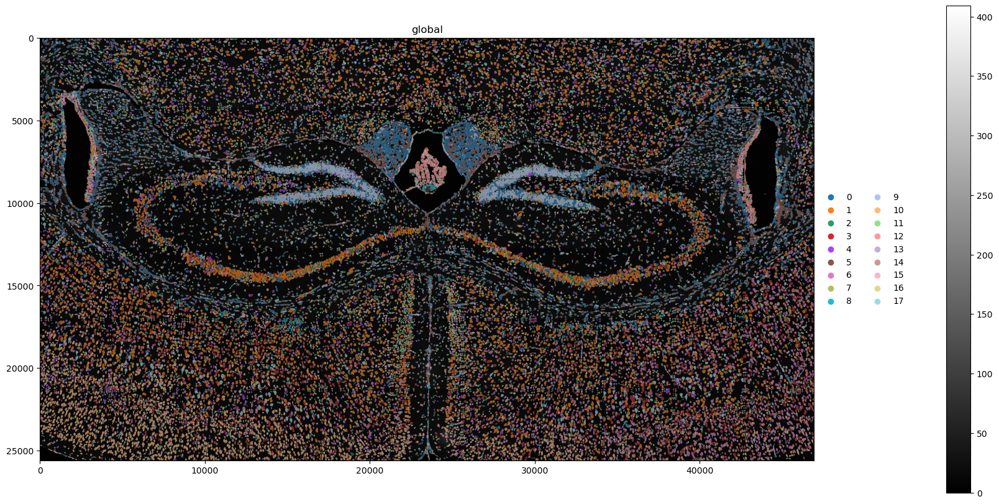

In [41]:
(
    sdata_quarterbrain
    .pl.render_images(channel="DNA", scale="scale4", cmap="gray")
    .pl.render_labels(scale="scale4", color="leiden", table="morphology_filtered")
    .pl.show(figsize=(16, 8))
)

/tmp/ipykernel_3656048/2692426009.py:54: RuntimeWarning: divide by zero encountered in divide
  scale = np.where(max_rgb > 1.0, 1.0 / max_rgb, 1.0)


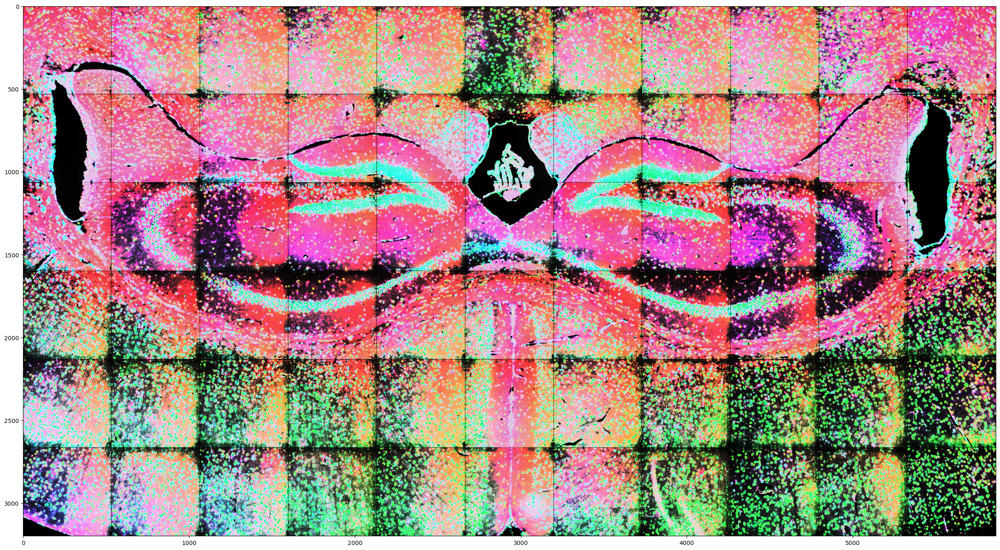

In [ ]:
import numpy as np


def auto_additive_blend_sane(
    channels: np.ndarray,
    palette: np.ndarray = None,
    p_low: float = 5.0, 
    p_high: float = 95,
    opacity: float = 0.5,
    log_compress: bool = True,
    log_k: float = 100.0,
) -> np.ndarray:
    """
    Blend C×H×W → H×W×3 with:
      1) default Tableau10-like palette
      2) percentile-based stretch [p_low,p_high]
      3) optional log1p compression
      4) per-channel opacity
      5) per-pixel max normalization to [0,1]
    """
    C, H, W = channels.shape

    # 1) default Tableau10-like palette
    if palette is None:
        hexes = [
            "#66C2A5",  # mint
            "#FC8D62",  # salmon
            "#8DA0CB",  # periwinkle
            "#E78AC3",  # pink
            "#A6D854",  # lime
]
        palette = np.array(
            [[int(h[i:i+2], 16) for i in (1, 3, 5)] for h in hexes],
            dtype=np.float32
        ) / 255.0
    palette = palette[:C]

    # 2–4) accumulate additive blend
    out = np.zeros((H, W, 3), dtype=np.float32)
    for i in range(C):
        ch = channels[i].astype(np.float32)
        lo, hi = np.percentile(ch, (p_low, p_high))
        # percentile stretch
        ch = np.clip((ch - lo) / (hi - lo), 0.0, 1.0)
        # optional log compression
        if log_compress:
            ch = np.log1p(ch * log_k) / np.log1p(log_k)
        # apply opacity & colorize
        out += (ch[..., None] * opacity) * palette[i]

    # 5) per-pixel max normalization
    #    so single-channel peaks hit 1.0, multi-channel sums get scaled down
    max_rgb = out.max(axis=-1, keepdims=True)
    scale = np.where(max_rgb > 1.0, 1.0 / max_rgb, 1.0)
    out *= scale

    # final clamp (safety)
    np.clip(out, 0.0, 1.0, out=out)
    return out


def hist_eq_channel(ch, n_bins=256):
    """
    Pure‐NumPy histogram equalization of a single 2D channel in [0,1].
    """
    # 1) build histogram
    flat = (ch * (n_bins-1)).astype(np.int32).ravel()
    hist = np.bincount(flat, minlength=n_bins)
    pdf = hist / hist.sum()

    # 2) compute CDF
    cdf = np.cumsum(pdf)
    cdf = (cdf - cdf.min()) / (cdf.max() - cdf.min())  # normalize to [0,1]

    # 3) map through CDF
    eq = cdf[flat].reshape(ch.shape)
    return eq.astype(np.float32)

def hist_equalize_rgb(img, n_bins=256):
    """
    Apply per‐channel histogram equalization to an H×W×3 float32 image in [0,1].
    """
    out = np.zeros_like(img, dtype=np.float32)
    for c in range(3):
        out[..., c] = hist_eq_channel(img[..., c], n_bins=n_bins)
    return out


data = auto_additive_blend_sane(np.array(sdata_quarterbrain["stitched_image"]["scale3"].image.data[:,:,:]))
rgb_eq = hist_equalize_rgb(data)

fig, ax = plt.subplots(figsize=(30, 30))

ax.imshow(rgb_eq)

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Your image has 5 channels. Using multichannel strategy 'pca' to project to RGB.                           


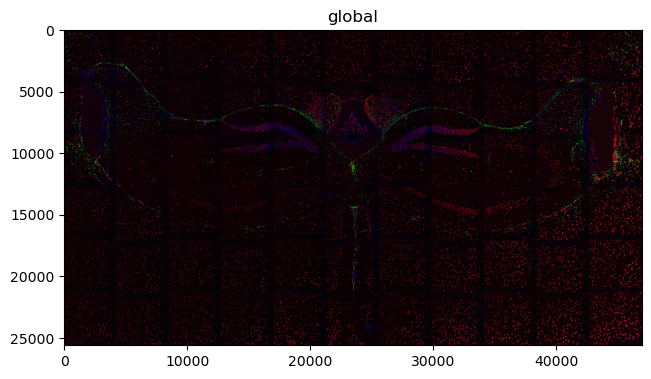

In [40]:
(
    sdata_quarterbrain
    .pl.render_images(
        # channel=["rRNA", "GFAP", "DNA", "G"],
        # palette=["red", "green", "blue", "orange"],
        multichannel_strategy="pca",
    )
    # .pl.render_labels()
    .pl.show()
)

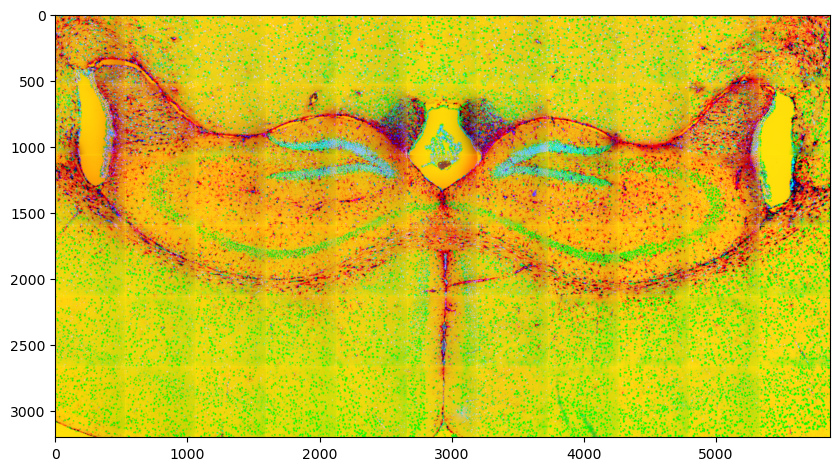

In [49]:

def img5_to_pca_rgb(
    channels: np.ndarray,
    threshold: float = 100,
    p_low: float = 2.0,
    p_high: float = 98.0,
    gamma: float = 0.5,
) -> np.ndarray:
    """
    PCA → RGB, ignoring background pixels defined by an intensity threshold.

    Parameters
    ----------
    channels : np.ndarray
        5×H×W array of your multichannel data.
    threshold : float
        Pixels where max(channels[:, y, x]) < threshold are treated as background
        (excluded from mean/SVD/percentile steps, and rendered as black).
    p_low, p_high : float
        Percentiles for clipping each PC into [0,1].
    gamma : float
        Final gamma correction (if ≠1, <1 brightens, >1 darkens midtones).

    Returns
    -------
    rgb : np.ndarray
        H×W×3 float32 image in [0,1].
    """
    C, H, W = channels.shape
    assert C == 5, "This function expects exactly 5 channels"

    # --- 0) build background mask from raw intensities ---
    # True = background (to ignore), False = signal
    bg_mask = np.max(channels, axis=0) < threshold

    # flatten channels to (5, H*W) and make a 1D valid mask
    X = channels.reshape(C, -1).astype(np.float32)
    valid = ~bg_mask.ravel()

    # --- 1) mean-center on valid pixels only ---
    mean = X[:, valid].mean(axis=1, keepdims=True)
    Xc = X - mean

    # --- 2) compute PCA via SVD on valid subset ---
    U, S, Vt = np.linalg.svd(Xc[:, valid], full_matrices=False)

    # --- 3) project all pixels onto first 3 PCs ---
    pcs = (U[:, :3].T @ Xc).reshape(3, H, W)

    # --- 4) percentile‐based stretch + gamma on each PC ---
    rgb = np.zeros((H, W, 3), dtype=np.float32)
    flat_valid = valid
    for i in range(3):
        pc = pcs[i].ravel()
        lo, hi = np.percentile(pc[flat_valid], (p_low, p_high))
        pc = np.clip((pc - lo) / (hi - lo), 0.0, 1.0)
        if gamma != 1.0:
            pc = pc ** (1.0 / gamma)
        rgb[..., i] = pc.reshape(H, W)

    return rgb

data = img5_to_pca_rgb(np.array(sdata_quarterbrain["stitched_image"]["scale3"].image.data[:,:,:]))

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(data)

In [8]:
sq.exp.calculate_image_features(
    sdata=sdata_quarterbrain,
    labels_key="segmentation",
    image_key="stitched_image",
    adata_key_added="morphology",
    n_jobs=20,
    show_progress_bar=True,
    scale="scale1"
)

INFO     Using '20' core(s).                                                                                       
INFO     Calculating 'skimage' label features.                                                                     


  0%|          | 0/38996 [00:00<?, ?/s]

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed i

KeyboardInterrupt: 

In [5]:
asas

NameError: name 'asas' is not defined

In [ ]:
# from SOPA, collapse

import logging
import re
from pathlib import Path

import dask.array as da
import numpy as np
import pandas as pd
import tifffile
import xarray as xr
from dask_image.imread import imread
from spatialdata import SpatialData
from spatialdata.models import Image2DModel, PointsModel

from sopa._constants import SopaAttrs
from sopa.io.reader.utils import _deduplicate_names, _default_image_kwargs

log = logging.getLogger(__name__)


def cosmx(
    path: str | Path,
    dataset_id: str | None = None,
    fov: int | None = None,
    read_proteins: bool = False,
    image_models_kwargs: dict | None = None,
    imread_kwargs: dict | None = None,
    flip_image: bool | None = None,
) -> SpatialData:
    """
    Read *Cosmx Nanostring* data. The fields of view are stitched together, except if `fov` is provided.

    This function reads the following files:
        - `*_fov_positions_file.csv` or `*_fov_positions_file.csv.gz`: FOV locations
        - `Morphology2D` directory: all the FOVs morphology images
        - `*_tx_file.csv.gz` or `*_tx_file.csv`: Transcripts location and names
        - If `read_proteins` is `True`, all the images under the nested `ProteinImages` directories will be read

        These files must be exported as flat files in AtomX. That is: within a study, click on "Export" and then select files from the "Flat CSV Files" section (transcripts flat and FOV position flat).

    Args:
        path: Path to the root directory containing *Nanostring* files.
        dataset_id: Optional name of the dataset (needs to be provided if not inferred).
        fov: Number of one single field of view to be read. If not provided, reads all FOVs and create a stitched image.
        read_proteins: Whether to read the proteins or the transcripts.
        image_models_kwargs: Keyword arguments passed to `spatialdata.models.Image2DModel`.
        imread_kwargs: Keyword arguments passed to `dask_image.imread.imread`.
        flip_image: For some buggy AtomX exports, `flip_image=True` has to be used for stitching. By default, the value is inferred based on the transcript file. See [this](https://github.com/gustaveroussy/sopa/issues/231) issue.

    Returns:
        A `SpatialData` object representing the CosMX experiment
    """
    path = Path(path)
    image_models_kwargs, imread_kwargs = _default_image_kwargs(image_models_kwargs, imread_kwargs)

    dataset_id = _infer_dataset_id(path, dataset_id)
    fov_locs = _read_fov_locs(path, dataset_id)

    protein_dir_dict = {}
    if read_proteins:
        protein_dir_dict = {
            int(protein_dir.parent.name[3:]): protein_dir for protein_dir in list(path.rglob("**/FOV*/ProteinImages"))
        }
        assert len(protein_dir_dict), f"No directory called 'ProteinImages' was found under {path}"

    if flip_image is None and not read_proteins:
        flip_image = _infer_flip_image(path, dataset_id)

    ### Read image(s)
    images_dir = _find_dir(path, "Morphology2D")
    morphology_coords = _cosmx_morphology_coords(images_dir)

    if fov is None:
        image, c_coords = _read_stitched_image(
            images_dir,
            fov_locs,
            protein_dir_dict,
            morphology_coords,
            flip_image,
            **imread_kwargs,
        )
        image_name = "stitched_image"
    else:
        log.info(f"Reading single FOV ({fov}), the image will not be stitched")
        fov_file = _find_matching_fov_file(images_dir, fov)

        image, c_coords = _read_fov_image(fov_file, protein_dir_dict.get(fov), morphology_coords, **imread_kwargs)
        image_name = f"F{fov:0>5}_image"

    parsed_image = Image2DModel.parse(image, dims=("c", "y", "x"), c_coords=c_coords, **image_models_kwargs)

    if read_proteins:
        return SpatialData(images={image_name: parsed_image}, attrs={SopaAttrs.CELL_SEGMENTATION: image_name})

    ### Read transcripts
    transcripts_data = _read_transcripts_csv(path, dataset_id)

    if fov is None:
        transcripts_data["x"] = transcripts_data["x_global_px"] - fov_locs["xmin"].min()
        transcripts_data["y"] = transcripts_data["y_global_px"] - fov_locs["ymin"].min()
        coordinates = None
        points_name = "points"
    else:
        transcripts_data = transcripts_data[transcripts_data["fov"] == fov]
        coordinates = {"x": "x_local_px", "y": "y_local_px"}
        points_name = f"F{fov:0>5}_points"

    from spatialdata_io._constants._constants import CosmxKeys

    transcripts = PointsModel.parse(
        transcripts_data,
        coordinates=coordinates,
        feature_key=CosmxKeys.TARGET_OF_TRANSCRIPT,
    )

    return SpatialData(
        images={image_name: parsed_image},
        points={points_name: transcripts},
        attrs={
            SopaAttrs.CELL_SEGMENTATION: image_name,
            SopaAttrs.TRANSCRIPTS: points_name,
            SopaAttrs.PRIOR_TUPLE_KEY: ("unique_cell_id", 0),
        },
    )


def _infer_dataset_id(path: Path, dataset_id: str | None) -> str:
    if isinstance(dataset_id, str):
        return dataset_id

    for suffix in [".csv", ".csv.gz"]:
        counts_files = list(path.rglob(f"[!\\.]*_fov_positions_file{suffix}"))

        if len(counts_files) == 1:
            found = re.match(rf"(.*)_fov_positions_file{suffix}", counts_files[0].name)
            if found:
                return found.group(1)

    raise ValueError("Could not infer `dataset_id` from the name of the transcript file. Please specify it manually.")


def _read_fov_image(
    morphology_path: Path, protein_path: Path | None, morphology_coords: list[str], **imread_kwargs
) -> tuple[da.Array, list[str]]:
    image = imread(morphology_path, **imread_kwargs)

    protein_names = []
    if protein_path is not None:
        protein_image, protein_names = _read_protein_fov(protein_path)
        image = da.concatenate([image, protein_image], axis=0)

    return image, _deduplicate_names(morphology_coords + protein_names)


def _read_fov_locs(path: Path, dataset_id: str) -> pd.DataFrame:
    fov_file = path / f"{dataset_id}_fov_positions_file.csv"

    if not fov_file.exists():
        fov_file = path / f"{dataset_id}_fov_positions_file.csv.gz"

    assert fov_file.exists(), f"Missing field of view file: {fov_file}"

    fov_locs = pd.read_csv(fov_file)
    fov_locs["xmax"] = 0.0  # will be filled when reading the images
    fov_locs["ymax"] = 0.0  # will be filled when reading the images

    fov_key, x_key, y_key, scale_factor = "fov", "x_global_px", "y_global_px", 1

    if not np.isin([fov_key, x_key, y_key], fov_locs.columns).all():  # try different column names
        fov_key, x_key, y_key = "FOV", "X_mm", "Y_mm"
        scale_factor = 1e3 / 0.120280945  # CosMX milimeters to pixels

        assert np.isin([fov_key, x_key, y_key], fov_locs.columns).all(), (
            f"The file {fov_file} must contain the following columns: {fov_key}, {x_key}, {y_key}. Consider using a different export module."
        )

    fov_locs.index = fov_locs[fov_key]
    fov_locs["xmin"] = fov_locs[x_key] * scale_factor
    fov_locs["ymin"] = fov_locs[y_key] * scale_factor

    return fov_locs


def _read_stitched_image(
    images_dir: Path,
    fov_locs: pd.DataFrame,
    protein_dir_dict: dict,
    morphology_coords: list[str],
    flip_image: int,
    **imread_kwargs,
) -> tuple[da.Array, list[str] | None]:
    fov_images = {}
    c_coords_dict = {}
    pattern = re.compile(r".*_F(\d+)")
    for image_path in images_dir.iterdir():
        if image_path.suffix == ".TIF":
            fov = int(pattern.findall(image_path.name)[0])

            image, c_coords = _read_fov_image(image_path, protein_dir_dict.get(fov), morphology_coords, **imread_kwargs)

            c_coords_dict[fov] = c_coords

            fov_images[fov] = da.flip(image, axis=1)

            fov_locs.loc[fov, "xmax"] = fov_locs.loc[fov, "xmin"] + image.shape[2]

            if flip_image:
                fov_locs.loc[fov, "ymax"] = fov_locs.loc[fov, "ymin"]
                fov_locs.loc[fov, "ymin"] = fov_locs.loc[fov, "ymax"] - image.shape[1]
            else:
                fov_locs.loc[fov, "ymax"] = fov_locs.loc[fov, "ymin"] + image.shape[1]

    for dim in ["x", "y"]:
        shift = fov_locs[f"{dim}min"].min()
        fov_locs[f"{dim}0"] = (fov_locs[f"{dim}min"] - shift).round().astype(int)
        fov_locs[f"{dim}1"] = (fov_locs[f"{dim}max"] - shift).round().astype(int)

    c_coords = list(set.union(*[set(names) for names in c_coords_dict.values()]))

    height, width = fov_locs["y1"].max(), fov_locs["x1"].max()
    stitched_image = da.zeros(shape=(len(c_coords), height, width), dtype=image.dtype)
    stitched_image = xr.DataArray(stitched_image, dims=("c", "y", "x"), coords={"c": c_coords})

    for fov, im in fov_images.items():
        xmin, xmax = fov_locs.loc[fov, "x0"], fov_locs.loc[fov, "x1"]
        ymin, ymax = fov_locs.loc[fov, "y0"], fov_locs.loc[fov, "y1"]

        if flip_image:
            y_slice, x_slice = slice(height - ymax, height - ymin), slice(width - xmax, width - xmin)
        else:
            y_slice, x_slice = slice(ymin, ymax), slice(xmin, xmax)

        stitched_image.loc[{"c": c_coords_dict[fov], "y": y_slice, "x": x_slice}] = im

        if len(c_coords_dict[fov]) < len(c_coords):
            log.warning(f"Missing channels ({len(c_coords) - len(c_coords_dict[fov])}) for FOV {fov}")

    return stitched_image.data, c_coords


def _find_matching_fov_file(images_dir: Path, fov: str | int) -> Path:
    assert isinstance(fov, int), "Expected `fov` to be an integer"

    pattern = re.compile(rf".*_F0*{fov}\.TIF")
    fov_files = [file for file in images_dir.rglob("*") if pattern.match(file.name)]

    assert len(fov_files), f"No file matches the pattern {pattern} inside {images_dir}"
    assert len(fov_files) == 1, f"Multiple files match the pattern {pattern}: {', '.join(map(str, fov_files))}"

    return fov_files[0]


def _read_transcripts_csv(path: Path, dataset_id: str, nrows: int | None = None) -> pd.DataFrame:
    transcripts_file = path / f"{dataset_id}_tx_file.csv.gz"

    if transcripts_file.exists():
        df = pd.read_csv(transcripts_file, compression="gzip", nrows=nrows)
    else:
        transcripts_file = path / f"{dataset_id}_tx_file.csv"
        assert transcripts_file.exists(), f"Transcript file {transcripts_file} not found."
        df = pd.read_csv(transcripts_file, nrows=nrows)

    TRANSCRIPT_COLUMNS = ["x_global_px", "y_global_px", "target"]
    assert np.isin(TRANSCRIPT_COLUMNS, df.columns).all(), (
        f"The file {transcripts_file} must contain the following columns: {', '.join(TRANSCRIPT_COLUMNS)}. Consider using a different export module."
    )

    df["unique_cell_id"] = df["fov"] * (df["cell_ID"].max() + 1) * (df["cell_ID"] > 0) + df["cell_ID"]

    return df


def _find_dir(path: Path, name: str):
    if (path / name).is_dir():
        return path / name

    paths = list(path.rglob(f"**/{name}"))
    assert len(paths) == 1, f"Found {len(paths)} path(s) with name {name} inside {path}"

    return paths[0]


def _cosmx_morphology_coords(images_dir: Path) -> list[str]:
    images_paths = list(images_dir.glob("*.TIF"))
    assert len(images_paths) > 0, f"Expected to find images inside {images_dir}"

    with tifffile.TiffFile(images_paths[0]) as tif:
        description = tif.pages[0].description

        substrings = re.findall(r'"BiologicalTarget": "(.*?)",', description)
        channels = re.findall(r'"ChannelId": "(.*?)",', description)
        channel_order = list(re.findall(r'"ChannelOrder": "(.*?)",', description)[0])

        return [substrings[channels.index(x)] for x in channel_order if x in channels]


def _get_cosmx_protein_name(image_path: Path) -> str:
    with tifffile.TiffFile(image_path) as tif:
        description = tif.pages[0].description
        substrings = re.findall(r'"DisplayName": "(.*?)",', description)
        return substrings[0]


def _read_protein_fov(protein_dir: Path) -> tuple[da.Array, list[str]]:
    images_paths = list(protein_dir.rglob("*.TIF"))
    protein_image = da.concatenate([imread(image_path) for image_path in images_paths], axis=0)
    channel_names = [_get_cosmx_protein_name(image_path) for image_path in images_paths]

    return protein_image, channel_names


def _infer_flip_image(path: Path, dataset_id: str) -> bool:
    df_ = _read_transcripts_csv(path, dataset_id, nrows=100)

    fov = df_["fov"].value_counts().index[0]
    df_ = df_[df_["fov"] == fov].sort_values("y_global_px")

    assert len(df_) > 1, f"Not transcripts in {fov=} to infer `flip_image`. Please provide `flip_image` manually."

    # in recent AtomX exports, y_local_px is negatively correlated with y_global_px
    flip_image = df_["y_local_px"].iloc[0] > df_["y_local_px"].iloc[-1]

    log.info(
        f"Inferring argument {flip_image=}. If the image stitching is wrong, please add a comment to https://github.com/gustaveroussy/sopa/issues/231"
    )

    return flip_image

In [ ]:
def stitch_segmentation_label_image(
    path: str | Path,
    fov_position_file: str | Path,
    cell_info_file: str | Path,
    dataset_id: str | None = None,
    seg_dir_name: str = "CellStatsDir",
    label_prefix: str = "CellLabels",
    flip_image: bool = False,
) -> tuple[da.Array, pd.DataFrame]:
    """
    Read per-FOV segmentation TIFFs, remap each cell’s local ID to a unique global ID,
    stitch into one big label image (with correct flip logic), and return the
    stitched Dask array plus your cell-info DataFrame annotated with `global_cell_id`.

    Args:
        path: root directory of your CosMX export
        fov_position_file: path to the *_fov_positions_file(.csv|.csv.gz)
        cell_info_file: path to your CSV (with columns fov, cellID, …)
        dataset_id: optional; if None inferred from the positions file
        seg_dir_name: folder holding FOVXXX subdirs
        label_prefix: e.g. "CellLabels" or "CompartmentLabels"
        flip_image: if True, inverts placement of each tile (matching SOPA logic)

    Returns:
        stitched_labels: dask.Array of shape (Y_total, X_total) with global IDs  
        annotated_df: your original DataFrame plus a `global_cell_id` column
    """
    path = Path(path)
    dataset_id = _infer_dataset_id(path, dataset_id)
    fov_locs = _read_fov_locs(Path(fov_position_file), dataset_id)

    # --- 1) load cell info & build mapping[fov]: localID -> globalID
    df = pd.read_csv(cell_info_file)
    mapping: dict[int, np.ndarray] = {}
    offset = 0
    for fov in sorted(df["fov"].unique()):
        local_ids = np.unique(df.loc[df["fov"] == fov, "cellID"].astype(int))
        if local_ids.size == 0:
            continue
        max_local = int(local_ids.max())
        arr_map = np.zeros(max_local + 1, dtype=int)
        for lid in local_ids:
            offset += 1
            arr_map[lid] = offset
        mapping[fov] = arr_map

    # annotate original DataFrame
    df = df.copy()
    df["global_cell_id"] = df.apply(lambda row: mapping[row["fov"]][int(row["cellID"])], axis=1)

    # --- 2) load & remap each tile, applying the SOPA flip-on-load
    seg_root = _find_dir(path, seg_dir_name)
    folder_re = re.compile(r"FOV0*(\d+)$", re.IGNORECASE)

    fov_tiles: dict[int, da.Array] = {}
    for sub in seg_root.iterdir():
        if not sub.is_dir():
            continue
        m = folder_re.match(sub.name)
        if not m:
            continue
        fov = int(m.group(1))

        tif_path = sub / f"{label_prefix}_F{fov:03d}.tif"
        if not tif_path.exists():
            raise FileNotFoundError(f"Expected {tif_path} for FOV {fov}")

        # read, remap local→global, then flip vertically (axis=0)
        arr = tifffile.imread(tif_path)
        arr = mapping[fov][arr]          # apply global IDs
        tile = da.from_array(arr, chunks=arr.shape)
        tile = da.flip(tile, axis=0)     # SOPA’s flip on the “y” axis

        fov_tiles[fov] = tile

        # update extents exactly as in SOPA’s _read_stitched_image
        y_size, x_size = arr.shape
        fov_locs.loc[fov, "xmax"] = fov_locs.loc[fov, "xmin"] + x_size
        if flip_image:
            fov_locs.loc[fov, "ymax"] = fov_locs.loc[fov, "ymin"]
            fov_locs.loc[fov, "ymin"] = fov_locs.loc[fov, "ymax"] - y_size
        else:
            fov_locs.loc[fov, "ymax"] = fov_locs.loc[fov, "ymin"] + y_size

    # --- 3) compute 0-based offsets (x0, x1, y0, y1)
    for dim in ("x", "y"):
        shift = fov_locs[f"{dim}min"].min()
        fov_locs[f"{dim}0"] = (fov_locs[f"{dim}min"] - shift).round().astype(int)
        fov_locs[f"{dim}1"] = (fov_locs[f"{dim}max"] - shift).round().astype(int)

    # --- 4) allocate stitched canvas
    total_y = int(fov_locs["y1"].max())
    total_x = int(fov_locs["x1"].max())
    stitched = da.zeros((total_y, total_x), dtype=next(iter(fov_tiles.values())).dtype)

    # --- 5) place each tile using SOPA’s placement logic
    for fov, tile in fov_tiles.items():
        x0, x1 = int(fov_locs.loc[fov, "x0"]), int(fov_locs.loc[fov, "x1"])
        y0, y1 = int(fov_locs.loc[fov, "y0"]), int(fov_locs.loc[fov, "y1"])
        if flip_image:
            y_slice = slice(total_y - y1, total_y - y0)
            x_slice = slice(total_x - x1, total_x - x0)
        else:
            y_slice = slice(y0, y1)
            x_slice = slice(x0, x1)
        stitched[y_slice, x_slice] = tile

    return stitched, df

## Quarter Brain

### Create labels image

In [ ]:
label, id_df = stitch_segmentation_label_image(
    "/lustre/groups/ml01/projects/2025_cpmeasure_for_spatial/data/raw/QuarterBrain_resegmented/",
    cell_info_file=Path("/lustre/groups/ml01/projects/2025_cpmeasure_for_spatial/data/raw/QuarterBrain_resegmented/Run5642_S3_Quarter-polygons.csv"),
    fov_position_file=Path("/lustre/groups/ml01/projects/2025_cpmeasure_for_spatial/data/raw/QuarterBrain_resegmented/"),
    dataset_id="Run5642_S3_Quarter"
)


In [ ]:
params = _default_image_kwargs()[0]
chunk_params = params["chunks"][1:]
scalefactor_params = params["scale_factors"]

quarterbrain_labels = Labels2DModel.parse(label, chunks=chunk_params, scale_factors=scalefactor_params)
quarterbrain_labels

INFO     no axes information specified in the object, setting `dims` to: ('y', 'x')                                


<xarray.DataTree>
Group: /
├── Group: /scale0
│       Dimensions:  (y: 25589, x: 46923)
│       Coordinates:
│         * y        (y) float64 205kB 0.5 1.5 2.5 3.5 ... 2.559e+04 2.559e+04 2.559e+04
│         * x        (x) float64 375kB 0.5 1.5 2.5 3.5 ... 4.692e+04 4.692e+04 4.692e+04
│       Data variables:
│           image    (y, x) int64 10GB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
├── Group: /scale1
│       Dimensions:  (y: 12794, x: 23461)
│       Coordinates:
│         * y        (y) float64 102kB 1.0 3.0 5.0 7.0 ... 2.558e+04 2.559e+04 2.559e+04
│         * x        (x) float64 188kB 1.0 3.0 5.0 7.0 ... 4.692e+04 4.692e+04 4.692e+04
│       Data variables:
│           image    (y, x) int64 2GB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
├── Group: /scale2
│       Dimensions:  (y: 6397, x: 11730)
│       Coordinates:
│         * y        (y) float64 51kB 2.0 6.0 10.0 ... 2.558e+04 2.558e+04 2.559e+04
│         * x        (x) float64 94kB 2.0 6.0 10.0 ... 4.691e+04 4.692e+04 4.692e+04
│       Data variables:
│           image    (y, x) int64 600MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
├── Group: /scale3
│       Dimensions:  (y: 3198, x: 5865)
│       Coordinates:
│         * y        (y) float64 26kB 4.001 12.0 20.0 ... 2.557e+04 2.558e+04 2.558e+04
│         * x        (x) float64 47kB 4.0 12.0 20.0 ... 4.69e+04 4.691e+04 4.692e+04
│       Data variables:
│           image    (y, x) int64 150MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
└── Group: /scale4
        Dimensions:  (y: 1599, x: 2932)
        Coordinates:
          * y        (y) float64 13kB 8.002 24.0 40.01 ... 2.555e+04 2.556e+04 2.558e+04
          * x        (x) float64 23kB 8.002 24.01 40.01 ... 4.688e+04 4.69e+04 4.691e+04
        Data variables:
            image    (y, x) int64 38MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>

### Create AnnData

In [ ]:
quarterbrain_df = pd.read_csv("/lustre/groups/ml01/projects/2025_cpmeasure_for_spatial/data/raw/QuarterBrain_resegmented/Run5642_S3_Quarter_exprMat_file.csv")

In [ ]:
quarterbrain_df.rename(columns={"cell_ID": "cellID"}, inplace=True)
quarterbrain_df

,fov,cellID,Chrna4,Slc6a1,Cd109,Ldha,Aldoc,Drd1,Tank,Rit2,...,NegPrb1,NegPrb2,NegPrb3,NegPrb4,NegPrb5,NegPrb6,NegPrb7,NegPrb8,NegPrb9,NegPrb10
0,1,0,57,810,42,349,9308,81,185,193,...,48,30,27,23,61,55,46,43,33,65
1,1,1,0,0,0,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,3,0,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,1,4,1,6,0,2,6,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39057,66,710,0,1,0,1,4,1,0,0,...,0,0,0,0,0,0,0,0,0,0
39058,66,711,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
39059,66,712,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
39060,66,713,0,0,0,0,2,0,1,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
id_df.drop_duplicates(
    subset=["fov", "cellID", "global_cell_id"],
    keep="first"
)

,fov,cellID,x_local_px,y_local_px,x_global_px,y_global_px,global_cell_id
0,1,1,50,4256,171450.000000,15597.666667,1
14,1,2,345,4256,171745.000000,15597.666667,2
28,1,3,529,4256,171929.000000,15597.666667,3
47,1,4,854,4256,172254.000000,15597.666667,4
70,1,5,1214,4256,172614.000000,15597.666667,5
...,...,...,...,...,...,...,...
927385,66,710,602,105,129335.333333,-9886.666667,38992
927412,66,711,4090,78,132823.333333,-9913.666667,38993
927434,66,712,909,41,129642.333333,-9950.666667,38994
927452,66,713,3349,25,132082.333333,-9966.666667,38995


In [ ]:
id_df = id_df.drop_duplicates(
    subset=["fov", "cellID", "global_cell_id"],
    keep="first" # not perfect, but we want a coordinate per cell
)
id_df = id_df.drop(columns=["x_local_px", "y_local_px"])
id_df

,fov,cellID,x_global_px,y_global_px,global_cell_id
0,1,1,171450.000000,15597.666667,1
14,1,2,171745.000000,15597.666667,2
28,1,3,171929.000000,15597.666667,3
47,1,4,172254.000000,15597.666667,4
70,1,5,172614.000000,15597.666667,5
...,...,...,...,...,...
927385,66,710,129335.333333,-9886.666667,38992
927412,66,711,132823.333333,-9913.666667,38993
927434,66,712,129642.333333,-9950.666667,38994
927452,66,713,132082.333333,-9966.666667,38995


In [ ]:
df_for_adata = id_df.merge(quarterbrain_df, on=["fov", "cellID"], how="left")

df_for_adata

,fov,cellID,x_global_px,y_global_px,global_cell_id,Chrna4,Slc6a1,Cd109,Ldha,Aldoc,...,NegPrb1,NegPrb2,NegPrb3,NegPrb4,NegPrb5,NegPrb6,NegPrb7,NegPrb8,NegPrb9,NegPrb10
0,1,1,171450.000000,15597.666667,1,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
1,1,2,171745.000000,15597.666667,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,3,171929.000000,15597.666667,3,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
3,1,4,172254.000000,15597.666667,4,1,6,0,2,6,...,0,0,0,0,0,0,0,0,0,0
4,1,5,172614.000000,15597.666667,5,0,0,1,2,3,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38991,66,710,129335.333333,-9886.666667,38992,0,1,0,1,4,...,0,0,0,0,0,0,0,0,0,0
38992,66,711,132823.333333,-9913.666667,38993,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
38993,66,712,129642.333333,-9950.666667,38994,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
38994,66,713,132082.333333,-9966.666667,38995,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
obs_cols = ["fov", "cellID", "global_cell_id", "x_global_px", "y_global_px"]
obs_for_adata = df_for_adata[obs_cols]
obs_for_adata["region"] = "segmentation"

obs_for_adata

/tmp/ipykernel_3670858/2704021236.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  obs_for_adata["region"] = "segmentation"


,fov,cellID,global_cell_id,x_global_px,y_global_px,region
0,1,1,1,171450.000000,15597.666667,segmentation
1,1,2,2,171745.000000,15597.666667,segmentation
2,1,3,3,171929.000000,15597.666667,segmentation
3,1,4,4,172254.000000,15597.666667,segmentation
4,1,5,5,172614.000000,15597.666667,segmentation
...,...,...,...,...,...,...
38991,66,710,38992,129335.333333,-9886.666667,segmentation
38992,66,711,38993,132823.333333,-9913.666667,segmentation
38993,66,712,38994,129642.333333,-9950.666667,segmentation
38994,66,713,38995,132082.333333,-9966.666667,segmentation


In [ ]:
quarterbrain_adata = ad.AnnData(
    df_for_adata.drop(columns=obs_cols),
    obs=obs_for_adata
)
quarterbrain_adata.uns["spatialdata_attrs"] = {
        "region": "segmentation", 
        "region_key": "region",
        "instance_key": "global_cell_id",
    }

quarterbrain_adata

/ictstr01/groups/ml01/projects/2025_cpmeasure_for_spatial/.pixi/envs/default/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 38996 × 960
    obs: 'fov', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'region'
    uns: 'spatialdata_attrs'

In [ ]:
quarterbrain_adata_model = TableModel.parse(quarterbrain_adata)

/ictstr01/groups/ml01/projects/2025_cpmeasure_for_spatial/.pixi/envs/default/lib/python3.11/site-packages/spatialdata/models/models.py:1144: UserWarning: Converting `region_key: region` to categorical dtype.
  return convert_region_column_to_categorical(adata)


### Load rest using SOPA

In [ ]:
quarterbrain_sdata = sopa.io.cosmx(
    path=quarterbrain_path,
    dataset_id="Run5642_S3_Quarter"
)

[INFO] (sopa.io.reader.cosmx) Inferring argument flip_image=np.False_. If the image stitching is wrong, please add a comment to https://github.com/gustaveroussy/sopa/issues/231


/ictstr01/groups/ml01/projects/2025_cpmeasure_for_spatial/.pixi/envs/default/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [ ]:
quarterbrain_sdata

SpatialData object
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 25589, 46923), (5, 12794, 23461), (5, 6397, 11730), (5, 3198, 5865), (5, 1599, 2932)
└── Points
      └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), points (Points)

### Combine everything

In [ ]:
quarterbrain_sdata_full = sd.SpatialData(
    images={"stitched_image": quarterbrain_sdata["stitched_image"]},
    labels={"segmentation": quarterbrain_labels},
    points={"points": quarterbrain_sdata["points"]},
    tables={"gexp": quarterbrain_adata},
)

In [ ]:
quarterbrain_sdata_full

SpatialData object
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 25589, 46923), (5, 12794, 23461), (5, 6397, 11730), (5, 3198, 5865), (5, 1599, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (25589, 46923), (12794, 23461), (6397, 11730), (3198, 5865), (1599, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (38996, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

#### Find spatially variables signal

In [ ]:
adata_tmp = quarterbrain_sdata_full.tables["gexp"]

adata_tmp.obsm["spatial"] = adata_tmp.obs[["x_global_px","y_global_px"]].values

sq.gr.spatial_neighbors(adata_tmp)
sq.gr.spatial_autocorr(
    adata_tmp,
    mode="moran",
    genes=adata_tmp.var_names,
    n_perms=10,
    n_jobs=1,
)

  0%|          | 0/10 [00:00<?, ?/s]

In [ ]:
print(adata_tmp.uns["moranI"])

                I  pval_norm  var_norm    pval_z_sim  pval_sim   var_sim  \
Ttr      0.617908   0.000000  0.000008  0.000000e+00  0.090909  0.000014   
Ppp3ca   0.543826   0.000000  0.000008  0.000000e+00  0.090909  0.000014   
Zbtb20   0.543421   0.000000  0.000008  0.000000e+00  0.090909  0.000022   
Camk2b   0.529537   0.000000  0.000008  0.000000e+00  0.090909  0.000012   
Camk2a   0.525296   0.000000  0.000008  0.000000e+00  0.090909  0.000013   
...           ...        ...       ...           ...       ...       ...   
Pirb     0.008677   0.000940  0.000008  4.087707e-07  0.090909  0.000003   
Cd84     0.008614   0.001014  0.000008  2.946088e-12  0.090909  0.000002   
NegPrb3  0.006717   0.008008  0.000008  7.835706e-03  0.090909  0.000008   
Csf3r    0.006330   0.011604  0.000008  3.710477e-05  0.090909  0.000003   
Ada      0.005526   0.023689  0.000008  1.623045e-02  0.090909  0.000006   

         pval_norm_fdr_bh  pval_z_sim_fdr_bh  pval_sim_fdr_bh  
Ttr              0.0000

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


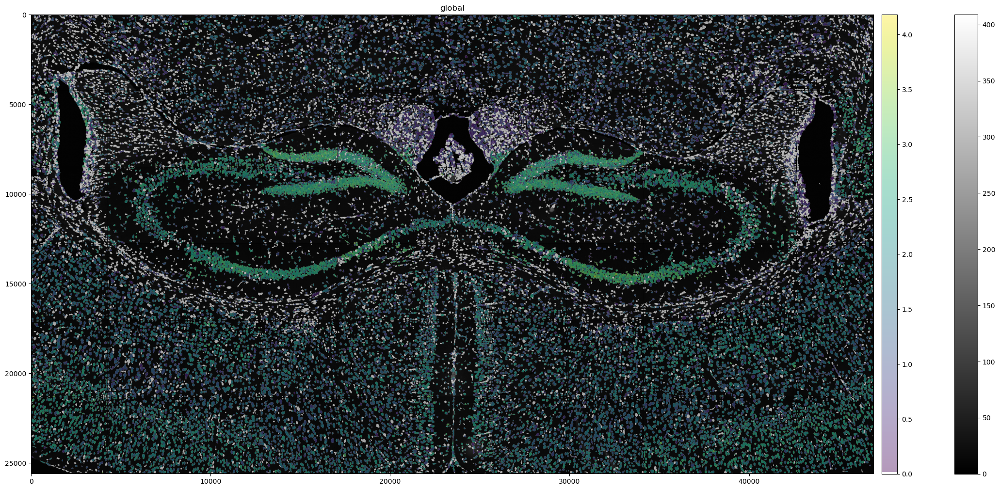

In [ ]:
from spatialdata_plot.pl.utils import set_zero_in_cmap_to_transparent

cmap = set_zero_in_cmap_to_transparent(plt.cm.viridis)

(
    quarterbrain_sdata_full
    .pl.render_images(channel=0, scale="scale4", cmap="gray")
    .pl.render_labels(scale="scale4", color="Ppp3ca", cmap=cmap)
    .pl.show(figsize=(20, 10))
)

In [ ]:
sc.pp.normalize_total(quarterbrain_sdata_full.tables["gexp"], inplace=True)
sc.pp.log1p(quarterbrain_sdata_full.tables["gexp"])
sc.pp.pca(quarterbrain_sdata_full.tables["gexp"])
sc.pp.neighbors(quarterbrain_sdata_full.tables["gexp"])
sc.tl.umap(quarterbrain_sdata_full.tables["gexp"])
sc.tl.leiden(quarterbrain_sdata_full.tables["gexp"])

/ictstr01/groups/ml01/projects/2025_cpmeasure_for_spatial/.pixi/envs/default/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


In [ ]:
quarterbrain_sdata_full.tables["gexp"]

AnnData object with n_obs × n_vars = 38996 × 960
    obs: 'fov', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'region', 'leiden'
    uns: 'spatialdata_attrs', 'spatial_neighbors', 'moranI', 'log1p', 'pca', 'neighbors', 'umap', 'leiden'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'spatial_connectivities', 'spatial_distances', 'distances', 'connectivities'

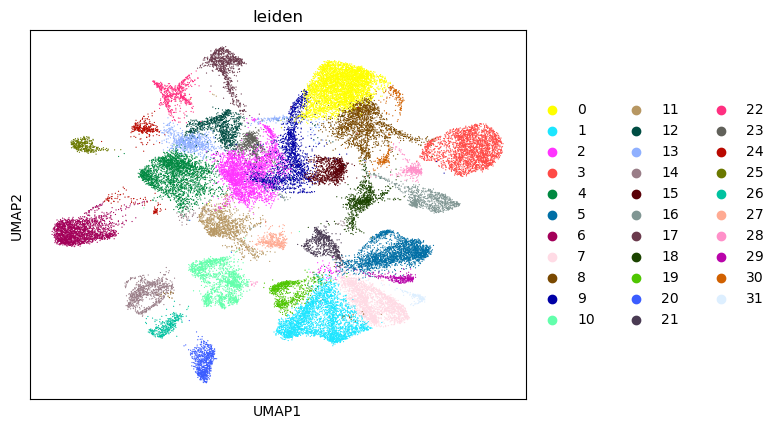

In [ ]:
sc.pl.umap(quarterbrain_sdata_full.tables["gexp"], color="leiden")

INFO     Rasterizing image for faster rendering.                                                                   


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/groups/ml01/projects/2025_cpmeasure_for_spatial/.pixi/envs/default/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:775: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


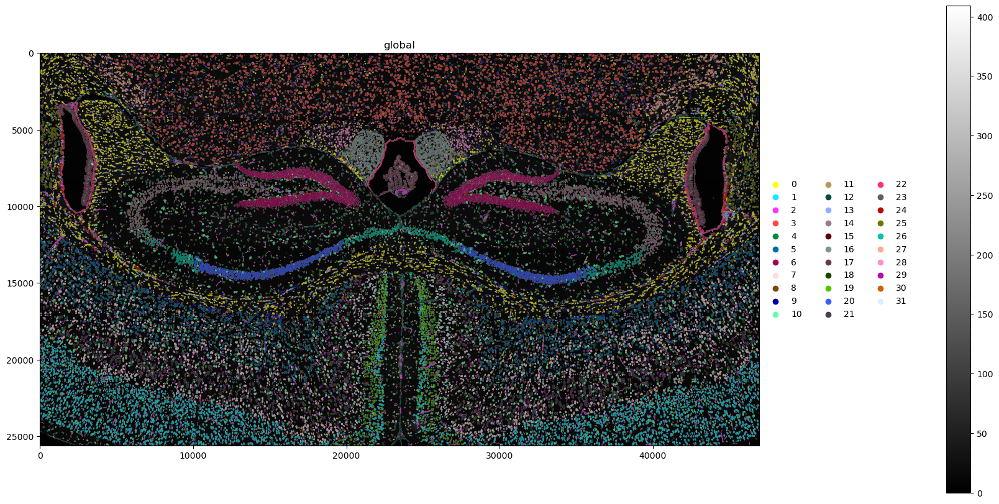

In [ ]:
(
    quarterbrain_sdata_full
    .pl.render_images(channel=0, scale="scale4", cmap="gray")
    .pl.render_labels(scale="scale4", color="leiden")
    .pl.show(figsize=(16, 8))
)

In [ ]:
quarterbrain_sdata_full.write(data_dir / "quarterbrain_sdata.zarr", overwrite=True)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /lustre/groups/ml01/projects/2025_cpmeasure_for_spatial/data/quarterbrain_sdata.zarr                      
